# 06 – Machine Learning (EVISION 360)

රටවල් ~60ක් පමණක් තියෙන data වලදී ML **ප්‍රවේශමෙන්** කරන්න ඕනේ. මේ notebook එකේ අරමුණ "හොඳම accuracy එක" නෙවෙයි, **මොනවා දන්නවාද, මොනවා දන්නේ නැද්ද** කියලා අවංකව පෙන්වීමයි.

| Part | ප්‍රශ්නය | Method |
| --- | --- | --- |
| A | රටවල් EV adoption profile එක අනුව කණ්ඩායම් වලට බෙදෙනවාද? | K-Means, silhouette, bootstrap stability, Ward සමඟ සසඳීම, PCA |
| B | අලුත් රටක adoption අනුමාන කරන්න පුළුවන්ද? කුමන සාධක වැදගත්ද? | Random Forest, Gradient Boosting, repeated CV, permutation importance |
| C | කාලය අනුව (2023–24) අනුමාන කරන්න පුළුවන්ද? | Time-based split + naive persistence baseline |
| D | අපේක්ෂාවට වඩා ඉහළ/පහළ adoption ඇති රටවල් | Out-of-fold residuals (exploratory) |

**XGBoost භාවිතා කරන්නේ නැහැ.** රටවල් 60/43ක data වලට ඒක අධික සංකීර්ණයි, ඒ නිසා sklearn වල Random Forest සහ ඉතා සරල Gradient Boosting පමණක් (සහ සරල baselines). **Random train/test split භාවිතා කරන්නේ නැහැ**: රටවල් අනුව (cross-validation) සහ කාලය අනුව (time split) validation කරනවා. ප්‍රතිඵල associations මිස causes නෙවෙයි.

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.decomposition import PCA
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.model_selection import GroupKFold, KFold
from sklearn.preprocessing import StandardScaler
from sqlalchemy import text

warnings.filterwarnings("ignore")
ROOT = Path("..").resolve()
sys.path.insert(0, str(ROOT / "src/ingestion"))
from db import get_engine

engine = get_engine()
FIG = ROOT / "reports/figures"; FIG.mkdir(parents=True, exist_ok=True)
OUT = ROOT / "data/processed"; OUT.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
SEED = 42

BG, PANEL, TXT, GRID = "#0b1426", "#0f1d36", "#e6f1ff", "#22345a"
CYAN, GREEN, AMBER, PINK, GREY = "#00e5ff", "#39ff88", "#ffb347", "#ff5ea8", "#8fa3c7"
plt.rcParams.update({
    "figure.facecolor": BG, "axes.facecolor": PANEL, "savefig.facecolor": BG, "text.color": TXT,
    "axes.labelcolor": TXT, "axes.edgecolor": GRID, "xtick.color": TXT, "ytick.color": TXT,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "grid.alpha": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 10, "axes.titlesize": 12,
    "axes.titleweight": "bold", "legend.facecolor": PANEL, "legend.edgecolor": GRID,
})


def q(sql, params=None):
    with engine.connect() as conn:
        conn.exec_driver_sql("SET search_path TO evision")
        return pd.read_sql(text(sql), conn, params=params)


def save(fig, name):
    fig.savefig(FIG / name, dpi=150, bbox_inches="tight"); print("saved", name)


def iea(parameter, mode, powertrain, table="fact_ev_market_annual"):
    return q(f"""
        SELECT g.geo_code, g.geo_name, f.year, f.value
        FROM {table} f JOIN dim_geography g USING (geo_key) JOIN dim_indicator i USING (indicator_key)
        JOIN dim_scenario s USING (scenario_key)
        WHERE i.parameter_code = :p AND i.vehicle_mode = :m AND i.powertrain = :pt
          AND s.scenario_code = 'Historical' AND g.geo_type = 'country' AND NOT f.is_suspect_value""",
             {"p": parameter, "m": mode, "pt": powertrain})


# Country-year feature table: EV share (target/profile) + World Bank structure + public charging points
share = iea("ev_sales_share", "Cars", "EV").rename(columns={"value": "share"})
econ = q("""SELECT g.geo_code, e.year, e.gdp_per_capita_usd, e.urban_pop_pct, e.population, e.inflation_pct
            FROM fact_economic_indicators e JOIN dim_geography g USING (geo_key) WHERE g.geo_type = 'country'""")
charging = pd.concat([iea("charging_points", "EVSE", pt, "fact_charging_infrastructure")
                      for pt in ["Publicly available fast", "Publicly available slow", "Publicly available ultra-fast"]])
charging = charging.groupby(["geo_code", "year"], as_index=False)["value"].sum().rename(columns={"value": "charging_points"})

data = share.merge(econ, on=["geo_code", "year"]).merge(charging, on=["geo_code", "year"], how="left")
data["log_gdp"] = np.log10(data["gdp_per_capita_usd"]); data["log_pop"] = np.log10(data["population"])
data["cp_per_100k"] = data["charging_points"] / data["population"] * 1e5
pp = (data["share"] / 100).clip(0.001, 0.999); data["logit"] = np.log(pp / (1 - pp))

x = data[data["year"] == 2024].reset_index(drop=True)            # 2024 cross-section
prev = data[data["year"] == 2021].set_index("geo_code")["share"]
x["change_pp"] = x["share"] - x["geo_code"].map(prev)            # share change 2021 -> 2024 (percentage points)
STRUCT = ["log_gdp", "urban_pop_pct", "log_pop", "inflation_pct"]
print(f"2024 countries: {len(x)} | missing share in 2021: {x['change_pp'].isna().sum()} | missing charging data: {x['cp_per_100k'].isna().sum()}")

2024 countries: 60 | missing share in 2021: 2 | missing charging data: 17


## A. Country clustering

**Features:** logit(EV share 2024), share change 2021→2024 (pp), log10 GDP per capita, urban %. හැම feature එකක්ම standardize කරනවා (K-Means distance based නිසා).

**k තෝරන්නේ කොහොමද?** එක මිනුමකට විතරක් විශ්වාස කරන්නේ නැහැ:
- **Silhouette** (−1 සිට 1): කණ්ඩායම් කොච්චර වෙන් වෙලාද (≈0.5+ හොඳයි, <0.25 කණ්ඩායම් ව්‍යුහයක් නැහැ)
- **Bootstrap stability (ARI)**: රටවල් නැවත sample කරලා නැවත cluster කළාම එකම බෙදීම ලැබෙනවාද (1 = හරියටම එකම)
- **Ward hierarchical** සමඟ එකඟතාව (ARI): වෙනත් algorithm එකකින් එකම ප්‍රතිඵලයද?

Countries clustered: 58
 k  inertia  silhouette  stability_ARI  stability_sd  agreement_with_Ward_ARI  smallest_cluster
 2   163.45        0.26           0.34          0.29                     0.57                26
 3   124.30        0.31           0.43          0.25                     0.14                10
 4    94.77        0.28           0.52          0.21                     0.37                 1
 5    79.19        0.26           0.49          0.20                     0.33                 1
 6    65.65        0.27           0.57          0.16                     0.65                 1
 7    55.95        0.27           0.63          0.15                     0.67                 1
saved 15_cluster_selection.png


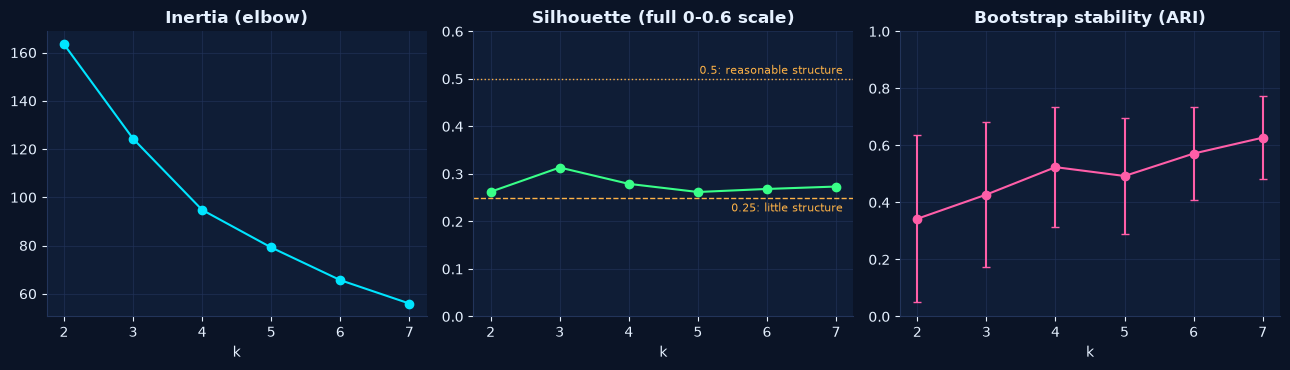

In [2]:
CL_FEATURES = ["logit", "change_pp", "log_gdp", "urban_pop_pct"]
c = x.dropna(subset=CL_FEATURES).reset_index(drop=True)
Z = StandardScaler().fit_transform(c[CL_FEATURES])
print(f"Countries clustered: {len(c)}")

rng = np.random.default_rng(SEED)
rows = []
for k in range(2, 8):
    km = KMeans(k, n_init=25, random_state=SEED).fit(Z)
    aris = []
    for _ in range(100):
        idx = rng.integers(0, len(Z), len(Z))
        kb = KMeans(k, n_init=10, random_state=SEED).fit(Z[idx])
        aris.append(adjusted_rand_score(km.labels_, kb.predict(Z)))
    ward = AgglomerativeClustering(k, linkage="ward").fit_predict(Z)
    rows.append({"k": k, "inertia": km.inertia_, "silhouette": silhouette_score(Z, km.labels_),
                 "stability_ARI": np.mean(aris), "stability_sd": np.std(aris),
                 "agreement_with_Ward_ARI": adjusted_rand_score(km.labels_, ward),
                 "smallest_cluster": int(np.bincount(km.labels_).min())})
sel = pd.DataFrame(rows)
print(sel.round(2).to_string(index=False))

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
axes[0].plot(sel["k"], sel["inertia"], color=CYAN, marker="o"); axes[0].set(title="Inertia (elbow)", xlabel="k")
axes[1].plot(sel["k"], sel["silhouette"], color=GREEN, marker="o")
axes[1].axhline(0.25, color=AMBER, ls="--", lw=1); axes[1].axhline(0.5, color=AMBER, ls=":", lw=1)
axes[1].text(7.1, 0.24, "0.25: little structure", color=AMBER, fontsize=8, ha="right", va="top")
axes[1].text(7.1, 0.505, "0.5: reasonable structure", color=AMBER, fontsize=8, ha="right", va="bottom")
axes[1].set(title="Silhouette (full 0-0.6 scale)", xlabel="k", ylim=(0, 0.6))
axes[2].errorbar(sel["k"], sel["stability_ARI"], yerr=sel["stability_sd"], color=PINK, marker="o", capsize=3)
axes[2].set(title="Bootstrap stability (ARI)", xlabel="k", ylim=(0, 1))
plt.tight_layout(); save(fig, "15_cluster_selection.png"); plt.show()

**කියවන විදිහ:** `smallest_cluster = 1` කියන්නේ ඒ k එකේදී රටක් පමණක් ඇති cluster එකක් (outlier එකක් වෙන් වී) තියෙනවා කියන එකයි, ඒ k අගයන් අර්ථවත් කණ්ඩායම් බෙදීමක් නෙවෙයි. Silhouette 0.5 ට බොහෝ අඩු නම් සහ stability ඉහළ නැත්නම්, රටවල් "ස්වභාවික කණ්ඩායම්" වලට බෙදෙන්නේ නැහැ, ඒවා අඛණ්ඩ spectrum එකක්. එහෙම නම් clusters ගන්න ඕනේ **විස්තරාත්මක බෙදීමක්** (descriptive segmentation) විදිහට මිසක් "සොයාගත් කණ්ඩායම්" විදිහට නෙවෙයි. කලින් blueprint එකේ තිබුණ නම් කරපු කණ්ඩායම් 4 (EV Leaders, Emerging...) data වලින් ශක්තිමත්ව සනාථ වෙනවාද කියලා මේකෙන් බලන්න පුළුවන්.

k = 3 (silhouette 0.31, stability ARI 0.43)
                    countries  median_share  median_change_pp  median_gdp_pc  median_urban_pct
segment                                                                                       
1: Lower adoption          12           5.7               2.3         6826.9              55.6
2: Middle adoption         36          12.0               5.2        32812.4              79.9
3: High adoption           10          49.0              20.0        62344.0              88.2
1: Lower adoption (12): South Africa, Philippines, India, Cambodia, Slovakia, Croatia, Romania, Poland, Indonesia, Slovenia, Thailand, Viet Nam
2: Middle adoption (36): Chile, Mexico, Russia, Japan, Malaysia, Bulgaria, Brazil, United Arab Emirates, Czechia, South Korea, Italy, Colombia, Estonia, United States, Türkiye, New Zealand, Spain, Greece, Australia, Cyprus, Latvia, Lithuania, Hungary, Uruguay, Costa Rica, Canada, Israel, Germany, Jordan, Austria, France, Ireland, Unite

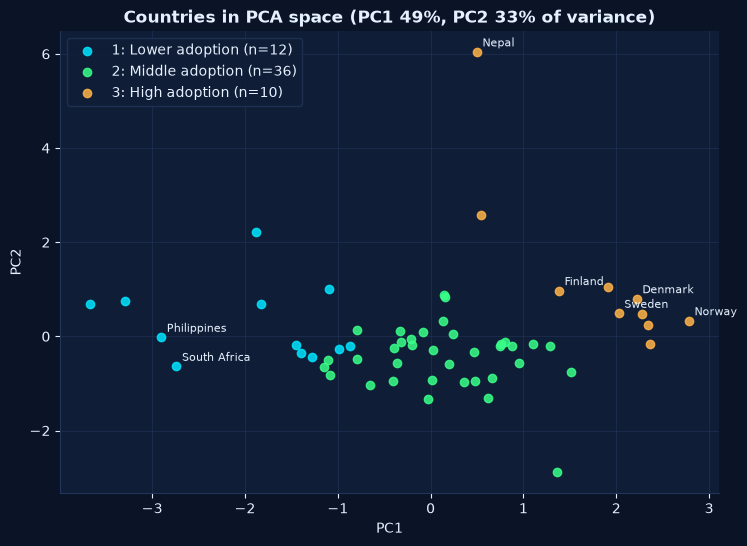

saved data/processed/country_segments_2024.csv


In [3]:
K = int(sel.loc[sel["silhouette"].idxmax(), "k"])      # highest silhouette; weak structure is reported below
km = KMeans(K, n_init=25, random_state=SEED).fit(Z)
c["cluster"] = km.labels_
order = c.groupby("cluster")["share"].median().sort_values().index.tolist()      # label segments by median adoption
names = {cl: f"{i + 1}: {label}" for i, (cl, label) in enumerate(zip(order, ["Lower adoption", "Middle adoption", "High adoption", "Top adoption", "Extreme", "Extreme+"][:K]))}
c["segment"] = c["cluster"].map(names)

profile = c.groupby("segment").agg(
    countries=("geo_code", "size"), median_share=("share", "median"), median_change_pp=("change_pp", "median"),
    median_gdp_pc=("gdp_per_capita_usd", "median"), median_urban_pct=("urban_pop_pct", "median"))
print(f"k = {K} (silhouette {sel.loc[sel['k'] == K, 'silhouette'].iloc[0]:.2f}, stability ARI {sel.loc[sel['k'] == K, 'stability_ARI'].iloc[0]:.2f})")
print(profile.round(1).to_string())
for seg, g in c.groupby("segment"):
    print(f"{seg} ({len(g)}):", ", ".join(g.sort_values("share")["geo_name"]))

pca = PCA(n_components=2, random_state=SEED).fit(Z)
P = pca.transform(Z)
print("PCA explained variance:", pca.explained_variance_ratio_.round(2), "| loadings:")
print(pd.DataFrame(pca.components_.T, index=CL_FEATURES, columns=["PC1", "PC2"]).round(2).to_string())

fig, ax = plt.subplots(figsize=(8.5, 6))
for (seg, g), col in zip(c.groupby("segment"), [CYAN, GREEN, AMBER, PINK, GREY, TXT]):
    ax.scatter(P[g.index, 0], P[g.index, 1], color=col, alpha=0.85, label=f"{seg} (n={len(g)})")
for i in c.nlargest(5, "share").index.tolist() + c.nsmallest(2, "share").index.tolist():
    ax.annotate(c.loc[i, "geo_name"], (P[i, 0], P[i, 1]), fontsize=8, xytext=(4, 4), textcoords="offset points")
ax.set(title=f"Countries in PCA space (PC1 {pca.explained_variance_ratio_[0]:.0%}, PC2 {pca.explained_variance_ratio_[1]:.0%} of variance)",
       xlabel="PC1", ylabel="PC2"); ax.legend()
save(fig, "16_country_segments_pca.png"); plt.show()

c[["geo_code", "geo_name", "segment", "share", "change_pp", "gdp_per_capita_usd", "urban_pop_pct"]].to_csv(OUT / "country_segments_2024.csv", index=False)
print("saved data/processed/country_segments_2024.csv")

**සටහන:** Segments නම් කරලා තියෙන්නේ median adoption අනුව (data වලින්ම), කලින් තීරණය කරපු නම් නෙවෙයි. ඒවා **descriptive** ඒවා. රටක් segment එකකට වැටීම "ස්වභාවික" කණ්ඩායමක සාමාජිකයෙක් වීම නෙවෙයි, සීමා රේඛා අහඹු ලෙස වෙනස් විය හැකියි (stability table බලන්න). Sri Lanka ට EV data නැති නිසා segment එකක් දෙන්නේ නැහැ, ඒක Phase 07 (Readiness Index) එකේදී structural සාධක වලින් බලනවා.

## B. අලුත් රටක adoption අනුමාන කරන්න පුළුවන්ද?

**Target:** EV share 2024 (pp). **Validation:** repeated 5-fold cross-validation (රටවල් 60ක cross-section එකක් නිසා එක row = එක රට, ඒ නිසා මේක country-grouped validation එකම). Repeat 20 වතාවක්, හැම repeat එකකම හැම රටක්ම එක වතාවක් held-out විදිහට අනුමාන වෙනවා.

**Metrics:** RMSE (percentage points) සහ **out-of-sample R²** (0 = "සාමාන්‍යය අනුමාන කිරීම" එක්ක සමානයි, negative = ඊට වඩා නරකයි).

**Models:** mean baseline, OLS (logit scale, Phase 05 එකේ model එක), Random Forest, සරල Gradient Boosting.

In [4]:
class MeanModel:
    def fit(self, X, y): self.m = float(np.mean(y)); return self
    def predict(self, X): return np.full(len(X), self.m)


class LogitOLS:
    """OLS on the logit scale, predictions back-transformed to share (pp)."""
    def fit(self, X, y):
        yy = np.clip(y / 100, 0.001, 0.999); self.m = LinearRegression().fit(X, np.log(yy / (1 - yy))); return self
    def predict(self, X): return 100 / (1 + np.exp(-self.m.predict(X)))


def make_rf(): return RandomForestRegressor(n_estimators=300, min_samples_leaf=3, random_state=SEED, n_jobs=-1)
def make_gbm(): return GradientBoostingRegressor(n_estimators=150, max_depth=2, learning_rate=0.05, subsample=0.8, random_state=SEED)


def repeated_cv(df, features, make_model, repeats=20, target="share"):
    """Out-of-fold predictions, repeated. Returns RMSE and R2 per repeat plus the mean OOF prediction per row."""
    X, y = df[features].values, df[target].values
    rmses, r2s, oof_all = [], [], []
    for rep in range(repeats):
        oof = np.zeros(len(df))
        for tr, te in KFold(5, shuffle=True, random_state=rep).split(X):
            oof[te] = make_model().fit(X[tr], y[tr]).predict(X[te])
        rmses.append(np.sqrt(np.mean((oof - y) ** 2))); r2s.append(1 - np.sum((y - oof) ** 2) / np.sum((y - y.mean()) ** 2))
        oof_all.append(oof)
    return np.array(rmses), np.array(r2s), np.mean(oof_all, axis=0)


def summarize(name, rmses, r2s):
    return {"model": name, "RMSE_pp": rmses.mean(), "RMSE_sd": rmses.std(), "OOS_R2": r2s.mean()}


xs = x.dropna(subset=STRUCT).reset_index(drop=True)
rows = []
for name, mk in {"Mean (baseline)": MeanModel, "OLS (logit)": LogitOLS, "Random Forest": make_rf, "Gradient Boosting": make_gbm}.items():
    r, r2, _ = repeated_cv(xs, STRUCT, mk); rows.append(summarize(name, r, r2))
cv_struct = pd.DataFrame(rows)
print(f"Structural features only {STRUCT}, n = {len(xs)}:")
print(cv_struct.round(2).to_string(index=False))

Structural features only ['log_gdp', 'urban_pop_pct', 'log_pop', 'inflation_pct'], n = 60:
            model  RMSE_pp  RMSE_sd  OOS_R2
  Mean (baseline)    19.29     0.25   -0.04
      OLS (logit)    19.59     0.69   -0.08
    Random Forest    17.82     0.42    0.11
Gradient Boosting    19.50     0.90   -0.07


**සටහන:** OOS R² කුඩා නම් (0 ට ආසන්න) සහ RMSE mean baseline එකට වඩා සුළු වශයෙන් පමණක් අඩු නම්, ආර්ථික සහ ජනගහන සාධක වලින් අලුත් රටක adoption "සාමාන්‍යය" ට වඩා හොඳින් අනුමාන කරන්න බැහැ. Gradient Boosting සහ OLS mean baseline එකටත් වඩා නරක වෙන්න පුළුවන් (overfitting). මේක Phase 05 (regression, leave-one-country-out) ප්‍රතිඵල එක්ක ගැලපෙනවාද කියලා table එකෙන් බලන්න.

### Charging infrastructure එකතු කළාම?

Public charging points per 100,000 people (IEA charging points ÷ World Bank population). Charging data ඇත්තේ රටවල් කීපයකට පමණයි, ඒ නිසා **එකම රටවල් subset එක මත** models සසඳනවා (සාධාරණ සැසඳීමක් සඳහා).

**අවවාදය:** Charging points සහ EV adoption එකිනෙකට බලපායි. EV වැඩි රටවල charger වැඩියෙන් ඉදි කරනවා (reverse causality). ඒ නිසා මේ සම්බන්ධය "charger හදලා adoption වැඩි කරන්න පුළුවන්" කියලා නෙවෙයි.

In [5]:
xc = x.dropna(subset=STRUCT + ["cp_per_100k"]).reset_index(drop=True)
missing = x[x["cp_per_100k"].isna()]
print(f"Subset with charging data: n = {len(xc)} (without: {len(missing)}). Median EV share: with {xc['share'].median():.1f}%, without {missing['share'].median():.1f}%"
      " -> the subset may not be representative of all countries")
FEATS = STRUCT + ["cp_per_100k"]
rows = []
for name, feats, mk in [("Mean (baseline)", STRUCT, MeanModel), ("OLS (logit), structural", STRUCT, LogitOLS),
                        ("Random Forest, structural", STRUCT, make_rf), ("OLS (logit), + charging", FEATS, LogitOLS),
                        ("Random Forest, + charging", FEATS, make_rf)]:
    r, r2, oof = repeated_cv(xc, feats, mk); rows.append(summarize(name, r, r2))
    if name == "Random Forest, + charging": oof_best = oof
cv_charge = pd.DataFrame(rows)
print(cv_charge.round(2).to_string(index=False))

Subset with charging data: n = 43 (without: 17). Median EV share: with 13.0%, without 10.0% -> the subset may not be representative of all countries
                    model  RMSE_pp  RMSE_sd  OOS_R2
          Mean (baseline)    19.98     0.34   -0.06
  OLS (logit), structural    17.18     0.66    0.22
Random Forest, structural    17.33     0.80    0.20
  OLS (logit), + charging    16.86     1.63    0.24
Random Forest, + charging    13.91     0.72    0.49


c:\Users\ishar\OneDrive - NSBM\Desktop\EVISION-360\EVISION-360\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\ishar\OneDrive - NSBM\Desktop\EVISION-360\EVISION-360\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\ishar\OneDrive - NSBM\Desktop\EVISION-360\EVISION-360\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the j

      feature  rmse_increase_pp  p2.5  p97.5
urban_pop_pct             -0.16 -1.39   0.24
inflation_pct             -0.02 -0.42   0.32
      log_pop              0.19 -0.99   1.44
      log_gdp              0.30 -0.60   1.76
  cp_per_100k              7.05  1.38  14.35
saved 17_permutation_importance.png


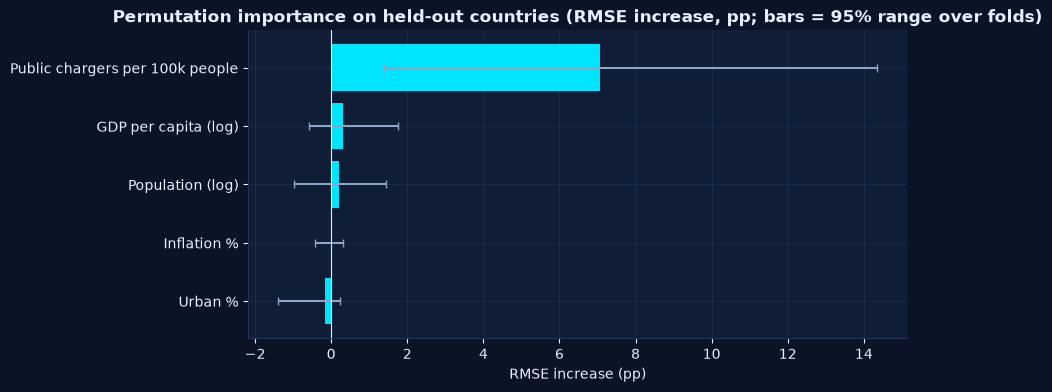

In [6]:
# Permutation importance on HELD-OUT folds: how much does RMSE rise when a feature is shuffled?
imps = []
for rep in range(10):
    for tr, te in KFold(5, shuffle=True, random_state=100 + rep).split(xc):
        m = make_rf().fit(xc[FEATS].values[tr], xc["share"].values[tr])
        r = permutation_importance(m, xc[FEATS].values[te], xc["share"].values[te], n_repeats=5, random_state=SEED,
                                   scoring="neg_root_mean_squared_error")
        imps.append(r.importances_mean)
imps = np.array(imps)
imp = pd.DataFrame({"feature": FEATS, "rmse_increase_pp": imps.mean(0),
                    "p2.5": np.percentile(imps, 2.5, axis=0), "p97.5": np.percentile(imps, 97.5, axis=0)}).sort_values("rmse_increase_pp")
print(imp.round(2).to_string(index=False))

labels = {"log_gdp": "GDP per capita (log)", "urban_pop_pct": "Urban %", "log_pop": "Population (log)",
          "inflation_pct": "Inflation %", "cp_per_100k": "Public chargers per 100k people"}
fig, ax = plt.subplots(figsize=(8.5, 4))
ax.barh([labels[f] for f in imp["feature"]], imp["rmse_increase_pp"], color=CYAN,
        xerr=[imp["rmse_increase_pp"] - imp["p2.5"], imp["p97.5"] - imp["rmse_increase_pp"]], ecolor=GREY, capsize=3)
ax.axvline(0, color=TXT, lw=0.8)
ax.set(title="Permutation importance on held-out countries (RMSE increase, pp; bars = 95% range over folds)", xlabel="RMSE increase (pp)")
save(fig, "17_permutation_importance.png"); plt.show()

**කියවන විදිහ:** Importance 0 ට ආසන්නයි නම් (සහ range එක 0 ඇතුළත් නම්) ඒ feature එක model එකේ අනුමානයට උදව් වෙන්නේ නැහැ. Importance එකෙන් කියන්නේ model එකට ඒ feature එක **කොච්චර ප්‍රයෝජනවත්ද** කියලා මිස ඒකෙන් adoption "සිදු වෙනවා" කියලා නෙවෙයි.

## C. කාලය අනුව validation (2023–24 අනුමාන කිරීම)

Time-based split: **2022 දක්වා** train කරලා **2023–2024** අනුමාන කරනවා (අනාගතය අතීතයෙන් පමණක් අනුමාන කරන විදිහ). ඊට අමතරව රටවල් අනුව validation (GroupKFold, 2018–2024 panel).

**Naive persistence baseline**: "2022 share එකම 2023–24 වලටත් කියන්න". ML model එකක් මේකට වඩා හොඳ නැත්නම් ඒකෙන් වැඩක් නැහැ.

Panel 402 country-years, 61 countries: Random Forest, unseen countries (GroupKFold): RMSE 16.3 pp, R2 -0.01

Time split (train <= 2022, test 2023-2024, 119 country-years, 60 countries):
                           method  RMSE_pp    R2
           Mean of training years    21.83 -0.31
Random Forest (structural + year)    14.37  0.43
         Persistence (2022 share)     8.88  0.78
saved 18_time_split_validation.png


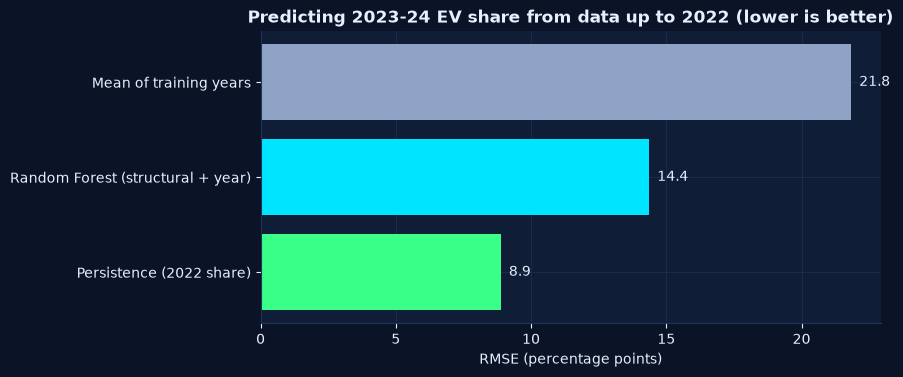

In [7]:
pn = data[data["year"].between(2018, 2024)].dropna(subset=STRUCT).reset_index(drop=True)
PF = STRUCT + ["year"]

# (i) country-grouped CV on the panel: can the model predict countries it has never seen?
oof = np.zeros(len(pn))
for tr, te in GroupKFold(5).split(pn, groups=pn["geo_code"]):
    oof[te] = make_rf().fit(pn[PF].values[tr], pn["share"].values[tr]).predict(pn[PF].values[te])
y = pn["share"].values
grp_rmse, grp_r2 = np.sqrt(np.mean((oof - y) ** 2)), 1 - np.sum((y - oof) ** 2) / np.sum((y - y.mean()) ** 2)
print(f"Panel {len(pn)} country-years, {pn['geo_code'].nunique()} countries: Random Forest, unseen countries (GroupKFold): RMSE {grp_rmse:.1f} pp, R2 {grp_r2:.2f}")

# (ii) time split: train <= 2022, test 2023-2024, on the SAME rows for every method
train, test = pn[pn["year"] <= 2022], pn[pn["year"] >= 2023]
last = train[train["year"] == 2022].set_index("geo_code")["share"]
test = test[test["geo_code"].isin(last.index)].copy()
preds = {
    "Mean of training years": np.full(len(test), train["share"].mean()),
    "Random Forest (structural + year)": make_rf().fit(train[PF].values, train["share"].values).predict(test[PF].values),
    "Persistence (2022 share)": test["geo_code"].map(last).values,
}
rows = [{"method": k, "RMSE_pp": np.sqrt(np.mean((v - test["share"].values) ** 2)),
         "R2": 1 - np.sum((test["share"].values - v) ** 2) / np.sum((test["share"].values - test["share"].mean()) ** 2)} for k, v in preds.items()]
tsplit = pd.DataFrame(rows)
print(f"\nTime split (train <= 2022, test 2023-2024, {len(test)} country-years, {test['geo_code'].nunique()} countries):")
print(tsplit.round(2).to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.barh(tsplit["method"][::-1], tsplit["RMSE_pp"][::-1], color=[GREEN, CYAN, GREY])
for i, v in enumerate(tsplit["RMSE_pp"][::-1]): ax.text(v + 0.3, i, f"{v:.1f}", va="center")
ax.set(title="Predicting 2023-24 EV share from data up to 2022 (lower is better)", xlabel="RMSE (percentage points)")
save(fig, "18_time_split_validation.png"); plt.show()

**සටහන:** Persistence baseline එක ML model එකට වඩා හොඳ නම්, ඉදිරි EV share forecasting (Phase 07) සඳහා **trend/time-series** ප්‍රවේශයක් (country-specific history) structural සාධක වලට වඩා ප්‍රයෝජනවත්. Structural ML models භාවිතා කළ යුත්තේ ඒවා baseline එකට වඩා හොඳ බව පෙන්වූවොත් පමණයි.

## D. අපේක්ෂාවට වඩා ඉහළ/පහළ adoption ඇති රටවල් (exploratory)

Charging සහිත Random Forest model එකේ **out-of-fold** අනුමානය (repeated CV එකේ සාමාන්‍යය) සමඟ සසඳලා: actual − predicted. ධනාත්මක = model එක බලාපොරොත්තු වුණාට වඩා ඉහළ adoption. **මෙය exploratory.** Model එකේ out-of-sample R² මධ්‍යස්ථයි, ඒ නිසා මේ ලැයිස්තුව "හේතු" ගැන කියන්නේ නැහැ, වැඩිදුර පරීක්ෂා කළ යුතු රටවල් පමණයි (policy, ආනයන බදු, ඉන්ධන මිල ආදිය model එකේ නැහැ).

In [8]:
xc = xc.assign(predicted=oof_best, residual=xc["share"] - oof_best)
cols = ["geo_name", "share", "predicted", "residual", "gdp_per_capita_usd", "cp_per_100k"]
print("Higher adoption than the model expects:"); print(xc.nlargest(6, "residual")[cols].round(1).to_string(index=False))
print(chr(10) + "Lower adoption than the model expects:"); print(xc.nsmallest(6, "residual")[cols].round(1).to_string(index=False))

Higher adoption than the model expects:
geo_name  share  predicted  residual  gdp_per_capita_usd  cp_per_100k
  Norway   92.0       40.0      52.0             89889.0        572.5
   China   48.0       20.9      27.1             13293.1        234.2
Portugal   33.0       15.1      17.9             29328.3        113.1
  Sweden   58.0       40.3      17.7             57222.7        436.2
 Finland   50.0       35.3      14.7             53155.5        291.8
  Jordan   21.0        7.9      13.1              5073.9          7.7

Lower adoption than the model expects:
     geo_name  share  predicted  residual  gdp_per_capita_usd  cp_per_100k
  South Korea    7.4       49.1     -41.7             36238.6        806.1
      Austria   24.0       46.8     -22.8             58268.9        299.6
        Italy    7.5       19.4     -11.9             40429.6        101.9
        Japan    2.8       12.9     -10.1             33797.1         25.8
United States   10.0       19.1      -9.1             8

## E. Findings (data වලින්ම ගණනය කරපු)

In [9]:
best_k = sel[sel["k"] == K].iloc[0]
rf_s = cv_struct[cv_struct["model"] == "Random Forest"].iloc[0]; mean_s = cv_struct[cv_struct["model"] == "Mean (baseline)"].iloc[0]
rf_c = cv_charge[cv_charge["model"] == "Random Forest, + charging"].iloc[0]; rf_cs = cv_charge[cv_charge["model"] == "Random Forest, structural"].iloc[0]
top_imp = imp.iloc[-1]; ts = tsplit.set_index("method")
print(f"1. Clustering: best k = {K}, but silhouette is only {best_k['silhouette']:.2f}, bootstrap stability ARI {best_k['stability_ARI']:.2f}, "
      f"agreement with Ward ARI {best_k['agreement_with_Ward_ARI']:.2f}. Countries form a continuum; segments are descriptive, not natural groups.")
print(f"2. Structural features only (GDP, urbanization, population, inflation): out-of-sample R2 of the best model is {max(cv_struct['OOS_R2']):.2f} "
      f"(Random Forest {rf_s['OOS_R2']:.2f}, RMSE {rf_s['RMSE_pp']:.1f} pp vs {mean_s['RMSE_pp']:.1f} pp for the mean) -> they predict unseen countries only weakly.")
print(f"3. With public chargers per 100k people (n = {len(xc)}): Random Forest RMSE {rf_c['RMSE_pp']:.1f} pp, R2 {rf_c['OOS_R2']:.2f} "
      f"(structural only on the same countries: {rf_cs['RMSE_pp']:.1f} pp, R2 {rf_cs['OOS_R2']:.2f}). Most important feature: {labels[top_imp['feature']]} "
      f"(+{top_imp['rmse_increase_pp']:.1f} pp RMSE when shuffled). Chargers and EVs influence each other, so this is not evidence that chargers cause adoption, and the {len(xc)} countries with charging data may not be representative.")
print(f"4. Forecasting 2023-24 from data up to 2022: persistence RMSE {ts.loc['Persistence (2022 share)', 'RMSE_pp']:.1f} pp vs Random Forest "
      f"{ts.loc['Random Forest (structural + year)', 'RMSE_pp']:.1f} pp and mean {ts.loc['Mean of training years', 'RMSE_pp']:.1f} pp.")
print(f"5. Unseen countries on the 2018-2024 panel (GroupKFold): Random Forest R2 {grp_r2:.2f}, RMSE {grp_rmse:.1f} pp.")

1. Clustering: best k = 3, but silhouette is only 0.31, bootstrap stability ARI 0.43, agreement with Ward ARI 0.14. Countries form a continuum; segments are descriptive, not natural groups.
2. Structural features only (GDP, urbanization, population, inflation): out-of-sample R2 of the best model is 0.11 (Random Forest 0.11, RMSE 17.8 pp vs 19.3 pp for the mean) -> they predict unseen countries only weakly.
3. With public chargers per 100k people (n = 43): Random Forest RMSE 13.9 pp, R2 0.49 (structural only on the same countries: 17.3 pp, R2 0.20). Most important feature: Public chargers per 100k people (+7.1 pp RMSE when shuffled). Chargers and EVs influence each other, so this is not evidence that chargers cause adoption, and the 43 countries with charging data may not be representative.
4. Forecasting 2023-24 from data up to 2022: persistence RMSE 8.9 pp vs Random Forest 14.4 pp and mean 21.8 pp.
5. Unseen countries on the 2018-2024 panel (GroupKFold): Random Forest R2 -0.01, RMSE 1

### Phase 07 වලට ඉගෙන ගත්ත දේ

- **EV Readiness Index**: Structural සාධක වලට (GDP, urbanization) adoption පැහැදිලි කිරීමේ බලය අඩුයි, ඒ නිසා index එකේ weights "model එකෙන් ආවා" කියලා කියන්න බැහැ. Weights ඒ විදිහටම ප්‍රකාශ කරලා sensitivity analysis (weights වෙනස් කළාම රටවල් ranking වෙනස් වෙන්නේ කොහොමද) පෙන්වන්න.
- **Charging infrastructure** index එකට එකතු කළ යුතු සාධකයක්, ඒත් එය adoption එක්ක අන්යෝන්‍ය වශයෙන් බලපාන බව ලියන්න (නැත්නම් circularity ගැටලුවක්).
- **Forecasting**: Persistence/trend baseline එක ජයගන්න අමාරුයි. Time-series forecasts (country-level history) සහ IEA scenarios (STEPS/CPS) සසඳන්න, structural ML models එයට කලින් baseline එක ජය ගත්තොත් විතරක්.